<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# Reconcile the debt level before explaining its change

Use Treasury’s Debt to the Penny records to reconcile total public debt with debt held by the public plus intragovernmental holdings, then separate their contributions to changes between reported dates. Keep the original currency strings and exact SQL decimals while using clearly labeled scaled values for charts.

**Recorded public data by default, not synthetic amounts.** The bundled original response was retrieved from the official Fiscal Data API for January 2024; its request, capture time and hash are recorded in [provenance](fixtures/provenance.json). The real published worker reads these rows through its supported local API override. Explicit live mode queries the same historical window at the official endpoint; failures never silently fall back to recorded data.

## Choose the inclusive report-date endpoint

`END_DATE` accepts an ISO date from **2024-01-03 through 2024-01-31**, default **2024-01-12**. The experiment uses **2024-01-19**. The start stays **2024-01-02**. These are source record dates, not a continuous daily series; weekends and other nonreporting dates are not filled.

`DATA_MODE` is **`recorded`** by default; choose **`live`** only for a separate official-API run. Both modes use the same bounded January window. Live results may be revised and are not an atomic snapshot. Restart and run all after editing.

In [1]:
END_DATE = "2024-01-12"
DATA_MODE = "recorded"

In [2]:
import json
from datetime import UTC, date, datetime
from decimal import Decimal
from pathlib import Path

import haybarn
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from notebook_support import finish, theme
from recorded_api import TreasurySource

assert DATA_MODE in {"recorded", "live"}
assert isinstance(END_DATE, str) and date.fromisoformat(END_DATE).isoformat() == END_DATE
assert "2024-01-03" <= END_DATE <= "2024-01-31"
RUN_UTC = datetime.now(UTC).isoformat()
source = TreasurySource(DATA_MODE)
SOURCE_STAMP = source.manifest["captured_at_utc"] if DATA_MODE == "recorded" else RUN_UTC
PROVENANCE = (
    f"Source: US Treasury Fiscal Data · {DATA_MODE} public response · {SOURCE_STAMP[:19]} UTC\n"
    "Debt to the Penny · USD source amounts · vgi-treasury / Haybarn / VGI"
)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = 0
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-treasury/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-treasury/notebooks/pyproject.toml.

## Attach the pinned public worker and retrieve every bounded match

The literal `uvx` command fetches a published Git revision with the tested VGI versions. The helper configures only documented Treasury source settings and restores them on cleanup. In recorded mode it filters and re-paginates the original rows through loopback HTTP, generating truthful local pagination envelopes. In live mode it selects the official HTTPS endpoint and disables the local override.

The request uses a fixed **four-row page size**, stable `record_date,src_line_nbr` ordering and **`max_rows := 0`**, meaning all matches inside the bounded date window. An explicit cap would return a prefix; SQL `LIMIT` alone is not an upstream cap. The worker checks page counts, page identities and repeated-page consistency. One visible CTAS materializes the source call before any display.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'treasury' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --with vgi-rpc==0.53.1 --from git+https://github.com/Query-farm/vgi-treasury@d5466e080cc8d241ced42b6d82d509c0b70766dc vgi-treasury-worker');
CREATE TABLE debt AS SELECT * FROM treasury.main.debt_to_penny(
 start_date:='2024-01-02',end_date:='{{ END_DATE }}',sort_fields:='record_date,src_line_nbr',
 page_size:=4,max_rows:=0);
CREATE TABLE dataset_info AS SELECT * FROM treasury.main.datasets(query:='debt_to_penny');

,Count


In [4]:
%%sql source_info <<
SELECT d.dataset,d.endpoint,d.amount_units,count(*) AS returned_rows,min(record_date) AS first_report,
 max(record_date) AS last_report,typeof(first(tot_pub_debt_out_amt)) AS sql_amount_type
FROM debt CROSS JOIN dataset_info d GROUP BY d.dataset,d.endpoint,d.amount_units;

In [5]:
display(source_info)
display(
    Markdown(
        f"**Mode: {DATA_MODE}.** Source timestamp: **{SOURCE_STAMP}**. "
        "Recorded mode uses the bundled capture time; live mode reports this run’s start time, "
        "not an atomic source timestamp."
    )
)

,dataset,endpoint,amount_units,returned_rows,first_report,last_report,sql_amount_type
0,debt_to_penny,v2/accounting/od/debt_to_penny,USD,9,2024-01-02,2024-01-12,"DECIMAL(38,2)"


**Mode: recorded.** Source timestamp: **2026-11-14T10:21:30.082156+00:00**. Recorded mode uses the bundled capture time; live mode reports this run’s start time, not an atomic source timestamp.

## Check the accounting identity in exact USD

The source amounts are **USD**, not millions. The typed table stores `DECIMAL(38,2)` values and retains each original JSON row. SQL checks `total = public + intragovernmental` and independently casts the original strings back to decimals.

The displayed amount columns are strings to retain every cent through pandas rendering. Converting to floating point is reserved for chart ratios and USD trillions/billions; the identity and change checks remain exact SQL decimal arithmetic. A debt stock is not annual spending or a budget deficit.

In [6]:
%%sql exact_rows <<
SELECT record_date,src_line_nbr,debt_held_public_amt::VARCHAR AS public_usd,
 intragov_hold_amt::VARCHAR AS intragovernmental_usd,tot_pub_debt_out_amt::VARCHAR AS total_usd,
 (tot_pub_debt_out_amt-debt_held_public_amt-intragov_hold_amt)::VARCHAR AS residual_usd,
 source_json::JSON->>'tot_pub_debt_out_amt' AS original_total_string
FROM debt ORDER BY record_date,src_line_nbr;

In [7]:
display(exact_rows)

,record_date,src_line_nbr,public_usd,intragovernmental_usd,total_usd,residual_usd,original_total_string
0,2024-01-02,1,26966333707733.52,7023793814333.31,33990127522066.83,0.00,33990127522066.83
1,2024-01-03,1,26967954226517.79,7026265646050.06,33994219872567.85,0.00,33994219872567.85
2,2024-01-04,1,26976928852286.78,7029342078398.78,34006270930685.56,0.00,34006270930685.56
3,2024-01-05,1,26976084404477.05,7033605651118.76,34009690055595.81,0.00,34009690055595.81
4,2024-01-08,1,26973939599749.78,7038259272542.18,34012198872291.96,0.00,34012198872291.96
5,2024-01-09,1,26974750049637.37,7050025008944.09,34024775058581.46,0.00,34024775058581.46
6,2024-01-10,1,26974362934797.17,7028075942693.64,34002438877490.81,0.00,34002438877490.81
7,2024-01-11,1,26985019110585.66,7073494783888.42,34058513894474.08,0.00,34058513894474.08
8,2024-01-12,1,26984681279437.27,7073476530013.90,34058157809451.17,0.00,34058157809451.17


## Keep levels and changes at different scales

The first chart shows the total’s composition on a zero-based scale in **USD trillions**. A nearly flat level does not imply small changes in dollars. The second chart therefore uses **USD billions** for differences between consecutive returned report dates. It is not a calendar-day rate: the gap column records how many calendar days each difference spans. Lines between reports guide the eye; no weekend debt values are invented.

In [8]:
%%sql
CREATE TABLE changes AS
SELECT *,lag(record_date) OVER w AS previous_report,
 date_diff('day',lag(record_date) OVER w,record_date) AS gap_days,
 debt_held_public_amt-lag(debt_held_public_amt) OVER w AS public_change_usd,
 intragov_hold_amt-lag(intragov_hold_amt) OVER w AS intragov_change_usd,
 tot_pub_debt_out_amt-lag(tot_pub_debt_out_amt) OVER w AS total_change_usd
FROM debt WINDOW w AS(ORDER BY record_date,src_line_nbr);
CREATE TABLE scaled AS SELECT record_date,previous_report,gap_days,
 debt_held_public_amt/1e12 AS public_trillions,intragov_hold_amt/1e12 AS intragov_trillions,
 tot_pub_debt_out_amt/1e12 AS total_trillions,
 public_change_usd/1e9 AS public_change_billions,intragov_change_usd/1e9 AS intragov_change_billions,
 total_change_usd/1e9 AS total_change_billions
FROM changes;

,Count


In [9]:
%%sql series <<
SELECT * FROM scaled ORDER BY record_date;

,record_date,previous_report,gap_days,public_trillions,intragov_trillions,total_trillions,public_change_billions,intragov_change_billions,total_change_billions
0,2024-01-02,NaT,<NA>,26.966334,7.023794,33.990128,NaN,NaN,NaN
1,2024-01-03,2024-01-02,1,26.967954,7.026266,33.994220,1.620519,2.471832,4.092351
2,2024-01-04,2024-01-03,1,26.976929,7.029342,34.006271,8.974626,3.076432,12.051058
3,2024-01-05,2024-01-04,1,26.976084,7.033606,34.009690,-0.844448,4.263573,3.419125
4,2024-01-08,2024-01-05,3,26.973940,7.038259,34.012199,-2.144805,4.653621,2.508817
5,2024-01-09,2024-01-08,1,26.974750,7.050025,34.024775,0.810450,11.765736,12.576186
6,2024-01-10,2024-01-09,1,26.974363,7.028076,34.002439,-0.387115,-21.949066,-22.336181
7,2024-01-11,2024-01-10,1,26.985019,7.073495,34.058514,10.656176,45.418841,56.075017
8,2024-01-12,2024-01-11,1,26.984681,7.073477,34.058158,-0.337831,-0.018254,-0.356085


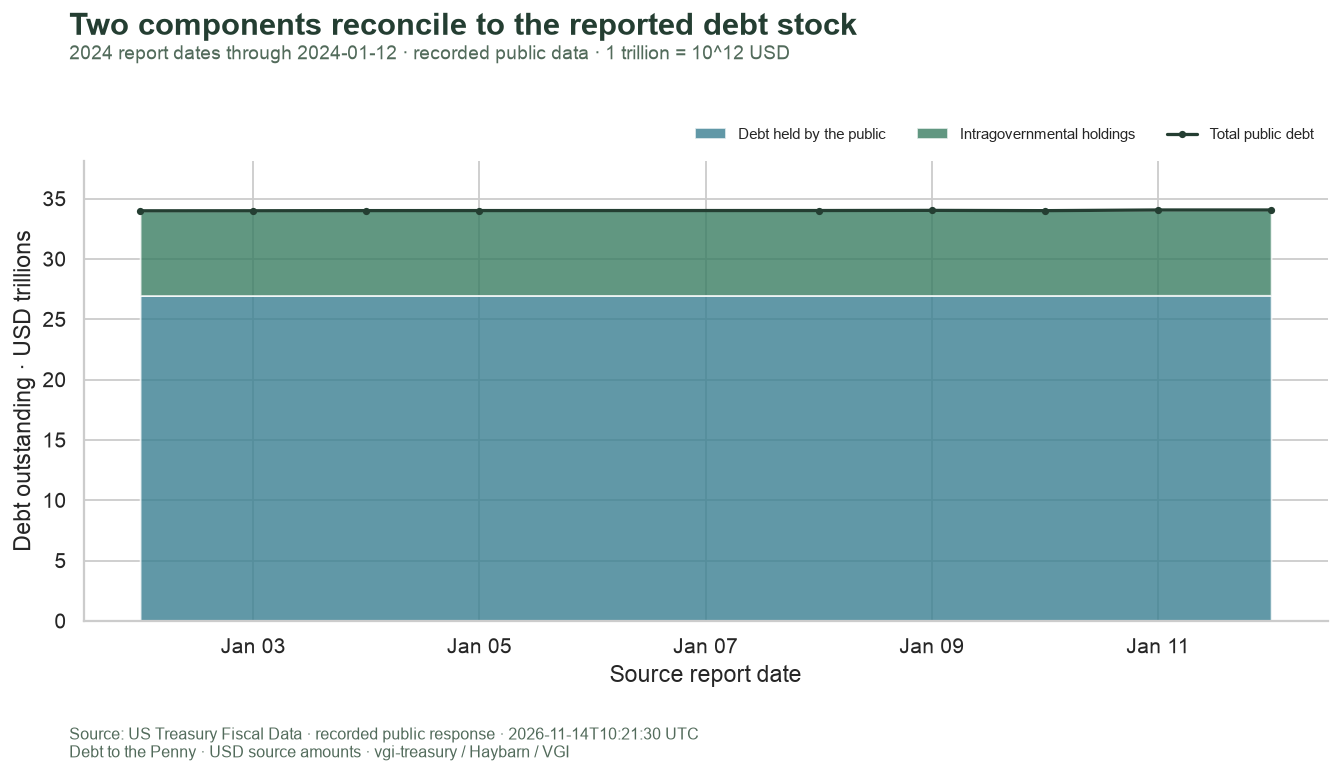

In [10]:
display(series)
fig, ax = plt.subplots(figsize=(11, 6))
ax.stackplot(
    series.record_date,
    series.public_trillions,
    series.intragov_trillions,
    colors=["#397f91", "#397d62"],
    alpha=0.8,
    labels=["Debt held by the public", "Intragovernmental holdings"],
)
ax.plot(
    series.record_date,
    series.total_trillions,
    color="#243e32",
    linewidth=1.8,
    marker="o",
    markersize=3,
    label="Total public debt",
)
ax.set(
    xlabel="Source report date", ylabel="Debt outstanding · USD trillions", ylim=(0, max(series.total_trillions) * 1.12)
)
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=7))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.01), frameon=False, ncol=3, fontsize=8.5)
finish(
    fig,
    f"debt-levels-{END_DATE}-{DATA_MODE}",
    "Two components reconcile to the reported debt stock",
    f"2024 report dates through {END_DATE} · {DATA_MODE} public data · 1 trillion = 10^12 USD",
    PROVENANCE,
)

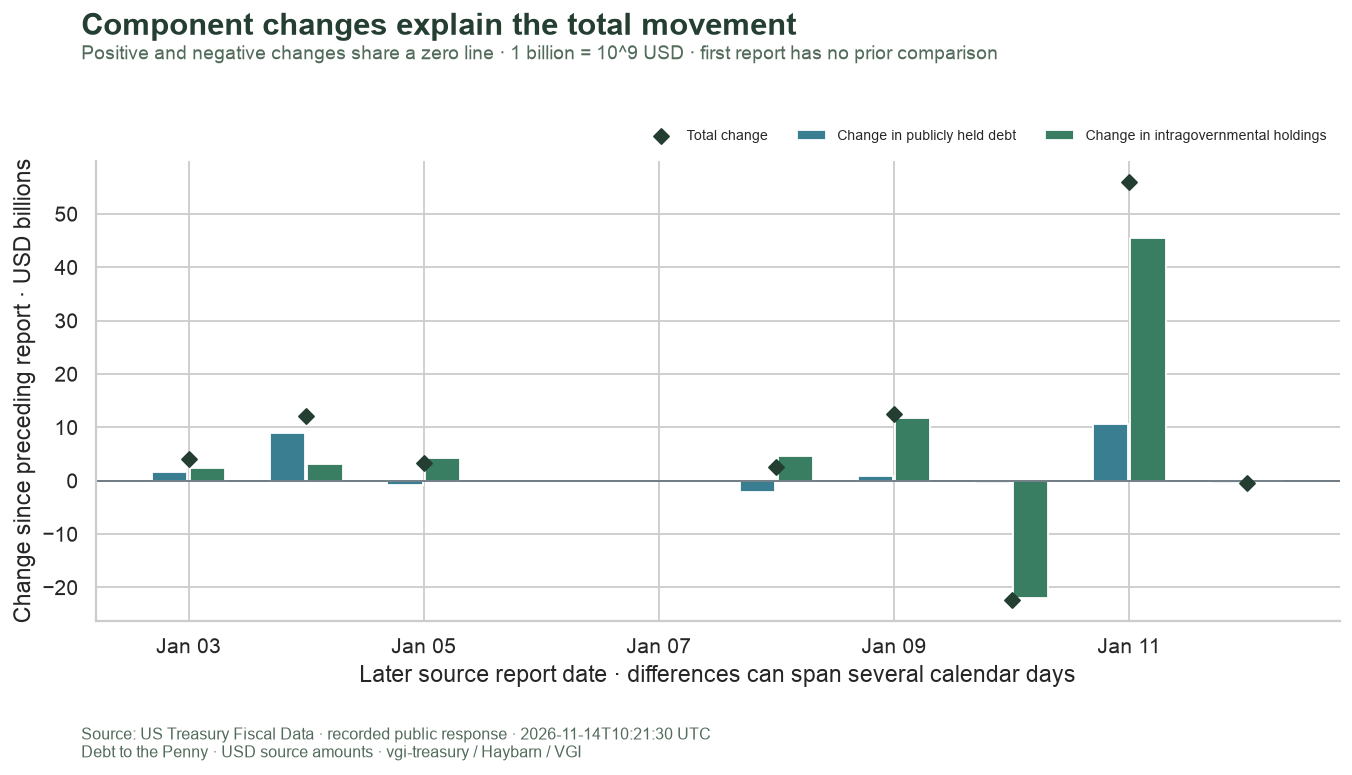

In [11]:
delta = series.loc[series.previous_report.notna()]
x = mdates.date2num(delta.record_date)
fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(x - 0.16, delta.public_change_billions, width=0.3, color="#397f91", label="Change in publicly held debt")
ax.bar(
    x + 0.16, delta.intragov_change_billions, width=0.3, color="#397d62", label="Change in intragovernmental holdings"
)
ax.scatter(x, delta.total_change_billions, marker="D", s=35, color="#243e32", label="Total change", zorder=4)
ax.axhline(0, color="#69757f", linewidth=1)
ax.set(
    xlabel="Later source report date · differences can span several calendar days",
    ylabel="Change since preceding report · USD billions",
)
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=7))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.01), frameon=False, ncol=3, fontsize=8)
finish(
    fig,
    f"debt-changes-{END_DATE}-{DATA_MODE}",
    "Component changes explain the total movement",
    "Positive and negative changes share a zero line · 1 billion = 10^9 USD · first report has no prior comparison",
    PROVENANCE,
)

In [12]:
%%sql summary <<
SELECT count(*) AS records,min(record_date) AS first_report,max(record_date) AS last_report,
 max(gap_days) AS longest_gap_days,
 (arg_max(tot_pub_debt_out_amt,record_date)-arg_min(tot_pub_debt_out_amt,record_date))::VARCHAR AS net_total_change_usd,
 sum(public_change_usd)::VARCHAR AS public_contribution_usd,sum(intragov_change_usd)::VARCHAR AS intragov_contribution_usd,
 sum(total_change_usd)::VARCHAR AS summed_total_change_usd
FROM changes;

In [13]:
display(summary)
s = summary.iloc[0]
display(
    Markdown(
        f"The extract contains **{int(s.records)} reports**, from **{s.first_report.date()}** to "
        f"**{s.last_report.date()}**. The endpoint difference is **{Decimal(s.net_total_change_usd):,.2f} USD**, "
        "which equals the sum of adjacent-report changes. "
        f"Publicly held debt contributes **{Decimal(s.public_contribution_usd):,.2f} USD** "
        f"and intragovernmental holdings **{Decimal(s.intragov_contribution_usd):,.2f} USD**. "
        f"The longest adjacent-report gap is **{int(s.longest_gap_days)} calendar days**. "
        "These arithmetic contributions describe changes in debt stocks; "
        "they do not by themselves identify spending, borrowing causes or fiscal sustainability."
    )
)

,records,first_report,last_report,longest_gap_days,net_total_change_usd,public_contribution_usd,intragov_contribution_usd,summed_total_change_usd
0,9,2024-01-02,2024-01-12,3,68030287384.34,18347571703.75,49682715680.59,68030287384.34


The extract contains **9 reports**, from **2024-01-02** to **2024-01-12**. The endpoint difference is **68,030,287,384.34 USD**, which equals the sum of adjacent-report changes. Publicly held debt contributes **18,347,571,703.75 USD** and intragovernmental holdings **49,682,715,680.59 USD**. The longest adjacent-report gap is **3 calendar days**. These arithmetic contributions describe changes in debt stocks; they do not by themselves identify spending, borrowing causes or fiscal sustainability.

## Verify source preservation, completeness and exact differences

These checks test relationships rather than a preferred direction or magnitude. Recorded mode also verifies the original response hash, returned-row count for the selected window, and the replay page sequence. Live mode relies on the worker’s upstream pagination checks and explicitly reports the fresh retrieval; it is never compared to fabricated replacement data.

In [14]:
%%sql checks <<
SELECT 'source keys are unique' AS check_name,
 (SELECT count(*)=count(DISTINCT struct_pack(record_date:=record_date,src_line_nbr:=src_line_nbr)) FROM debt) AS passed
UNION ALL SELECT 'one report per date for this dataset',(SELECT count(*)=count(DISTINCT record_date) FROM debt)
UNION ALL SELECT 'all rows stay within requested bounds',
 (SELECT bool_and(record_date BETWEEN DATE '2024-01-02' AND DATE '{{ END_DATE }}') FROM debt)
UNION ALL SELECT 'source units are USD',(SELECT bool_and(amount_units='USD') FROM debt)
UNION ALL SELECT 'amount columns preserve decimal cents',
 (SELECT typeof(first(tot_pub_debt_out_amt))='DECIMAL(38,2)' FROM debt)
UNION ALL SELECT 'required accounting components are present',
 (SELECT bool_and(debt_held_public_amt IS NOT NULL AND intragov_hold_amt IS NOT NULL AND tot_pub_debt_out_amt IS NOT NULL) FROM debt)
UNION ALL SELECT 'total equals its components exactly',
 (SELECT bool_and(tot_pub_debt_out_amt=debt_held_public_amt+intragov_hold_amt) FROM debt)
UNION ALL SELECT 'original total string round-trips exactly',
 (SELECT bool_and(tot_pub_debt_out_amt=(source_json::JSON->>'tot_pub_debt_out_amt')::DECIMAL(38,2)) FROM debt)
UNION ALL SELECT 'both original component strings round-trip exactly',
 (SELECT bool_and(debt_held_public_amt=(source_json::JSON->>'debt_held_public_amt')::DECIMAL(38,2)
 AND intragov_hold_amt=(source_json::JSON->>'intragov_hold_amt')::DECIMAL(38,2)) FROM debt)
UNION ALL SELECT 'first difference is missing rather than zero',
 (SELECT count(*) FILTER(WHERE previous_report IS NULL AND total_change_usd IS NULL)=1 FROM changes)
UNION ALL SELECT 'component differences reconcile exactly',
 (SELECT bool_and(total_change_usd=public_change_usd+intragov_change_usd) FROM changes WHERE previous_report IS NOT NULL)
UNION ALL SELECT 'adjacent differences telescope to endpoint change',
 (SELECT sum(total_change_usd)=arg_max(tot_pub_debt_out_amt,record_date)-arg_min(tot_pub_debt_out_amt,record_date) FROM changes);

In [15]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks
assert len(series) >= 2
if DATA_MODE == "recorded":
    expected = [r for r in source.recorded["data"] if "2024-01-02" <= r["record_date"] <= END_DATE]
    assert len(series) == len(expected)
    assert [r["page"] for r in source.requests] == list(range(1, (len(expected) + 3) // 4 + 1))
    assert all(r["page_size"] == 4 and r["total"] == len(expected) for r in source.requests)
    display(source.requests)
display(
    Markdown(
        f"**{len(checks)} SQL checks passed**. "
        + (
            "Recorded response hash, row count and page-sequence checks also passed."
            if DATA_MODE == "recorded"
            else "Live official-API retrieval completed without fallback; worker pagination checks remained enabled."
        )
    )
)
Path("validation/source-run.json").write_text(
    json.dumps(
        {
            "mode": DATA_MODE,
            "source_timestamp": SOURCE_STAMP,
            "end_date": END_DATE,
            "rows": len(series),
            "recorded_page_journal": source.requests,
        },
        indent=2,
    )
    + "\n"
)

,check_name,passed
0,source keys are unique,True
1,one report per date for this dataset,True
2,all rows stay within requested bounds,True
3,source units are USD,True
4,amount columns preserve decimal cents,True
5,required accounting components are present,True
6,total equals its components exactly,True
7,original total string round-trips exactly,True
8,both original component strings round-trip exa...,True
9,first difference is missing rather than zero,True


[{'page': 1,
  'page_size': 4,
  'rows': 4,
  'total': 9,
  'start': '2024-01-02',
  'end': '2024-01-12'},
 {'page': 2,
  'page_size': 4,
  'rows': 4,
  'total': 9,
  'start': '2024-01-02',
  'end': '2024-01-12'},
 {'page': 3,
  'page_size': 4,
  'rows': 1,
  'total': 9,
  'start': '2024-01-02',
  'end': '2024-01-12'}]

**12 SQL checks passed**. Recorded response hash, row count and page-sequence checks also passed.

583

## Focused experiment: include one more report week

Change only **`END_DATE` from `2024-01-12` to `2024-01-19`**, leaving `DATA_MODE = "recorded"`, and restart/run all. Predict more returned reports and at least one additional four-row page. Compare net component contributions and the endpoint difference; no direction of debt movement is presumed.

Rows and adjacent-report differences through January 12 should match the shorter run exactly because both use the same capture. The first returned row still has no earlier comparator. Differences across a weekend or nonreporting date remain multi-day changes, not daily rates. Restore **`2024-01-12`** for the default. The README saves this experiment and a distinct live validation run separately.

In [16]:
connection.close()
source.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>